![Banner](images/09_distributed_spatial_datas.png)

# Spatial SQL on Spark with Apache Sedona

Dask is not the only engine for large spatial data. Many organisations keep their data in a data
lake processed by **Apache Spark**, and **Apache Sedona** adds spatial types, spatial SQL
functions, spatial partitioning and spatial joins to Spark. When the data already live there, or
when both sides of a join are too large for one machine, Sedona is the natural tool. This notebook
starts a Sedona session from `geolattice.distributed.sedona`, runs the same spatial joins with
Sedona and with GeoLattice's Dask engine, writes spatial SQL over the New York taxi zones and 38
million trips, and reads and writes GeoParquet from Spark.

## Overview

### Spark's model

| Part | Role |
|---|---|
| **Driver** | the program you write; plans the job |
| **Executors** | JVM processes (on this machine: threads of one JVM in `local[*]` mode) that run tasks |
| **Partitions** | slices of a DataFrame; one task per partition per stage |
| **Shuffle** | moves rows between partitions between stages (joins, group-bys) |
| **Lazy plans** | transformations build a plan; actions (`count`, `collect`, `write`) run it, after the Catalyst optimizer has rewritten it |

### What Sedona adds

- A geometry type and about 200 `ST_` functions (`ST_Contains`, `ST_Intersects`, `ST_DWithin`,
  `ST_Buffer`, `ST_Area`, `ST_Transform`, ...), callable from SQL and the DataFrame API.
- **Spatial joins**: when a join condition is a spatial predicate, Sedona partitions both sides
  spatially (KDB-tree or quadtree grids), builds an index per partition and tests only matching
  partitions. A small side can instead be **broadcast** to every executor.
- GeoParquet and shapefile readers and writers, and raster functions.

### Spark or Dask?

| Situation | Better fit |
|---|---|
| data already in a Spark lake, SQL users, a Databricks or EMR cluster | Spark with Sedona |
| both sides of a join have hundreds of millions of rows | Spark with Sedona (spatial partitioning of both sides) |
| one side is small (zones, counties, facilities) | either; Dask sends the small side to every task |
| rasters, NumPy and GPU work, Python-first workflows | Dask (and GeoLattice) |

Moving data between Python and the JVM is not free: GeoPandas frames are serialized (with Arrow)
on the way in and out. A fair comparison counts that cost.

## Sedona with GeoLattice

| Function | Does |
|---|---|
| `pdist.sedona.spark(master=, config=)` | starts (or reuses) a Sedona-enabled Spark session; the Sedona JARs matching the installed versions are fetched from Maven on first use |
| `pdist.sedona.to_spark(gdf)`, `to_geopandas(sdf)` | GeoDataFrame to Spark DataFrame and back (GeoArrow when available) |
| `pdist.sedona.sjoin(left, right, predicate=)` | spatial join as Spark SQL; GeoPandas in gives GeoPandas out with `geopandas.sjoin`'s columns, Spark in gives a lazy Spark DataFrame |
| `pdist.vector.sjoin(..., engine="sedona")` | the same, from the Dask API; `engine="auto"` picks Sedona when an input is a Spark DataFrame |
| `pdist.sedona.is_spark(obj)`, `stop()` | type check; shut the session down |

Installation: `pip install "geolattice[distributed-spark]"` (PySpark and apache-sedona) and a Java
17 or newer runtime.

### Learning objectives

1. Describe Spark's driver, executors, partitions and shuffles, and what Sedona adds.
2. Start a Sedona session and move GeoDataFrames into and out of Spark.
3. Run the same spatial join with Sedona and with Dask, check that the results agree, and compare
   the costs.
4. Write spatial SQL with `ST_` functions on zones and trips.
5. Read and write GeoParquet from Spark.

### Data

| Dataset | Content |
|---|---|
| Kansas building footprints and counties | 1.6 million polygons; 105 county polygons (EPSG:5070) |
| NYC taxi zones and 2023 trips | 263 zones; 38.3 million trips (Parquet) |

### Contents

- Setup
- A Sedona session
- Buildings by county: Sedona and Dask
- Joining two Spark DataFrames
- Spatial SQL on taxi zones and trips
- GeoParquet in and out of Spark
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import os  # environment variables for Spark
import shutil  # remove scratch files
SP = OUT / "sedona"  # scratch folder
SP.mkdir(parents=True, exist_ok=True)  # create it


def timed(fn):  # wall time and result of one call
    t = time.perf_counter(); out = fn(); return time.perf_counter() - t, out  # time it

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)


## A Sedona session

`pdist.sedona.spark` starts Spark in local mode on all cores (`local[*]`) with Sedona registered.
The configuration gives the driver JVM 24 GB of memory and sets the number of shuffle partitions.

In [2]:
print("Maven packages:", pdist.sedona.packages())  # matched to the installed Sedona and PySpark
t0 = time.perf_counter()  # start
spark = pdist.sedona.spark("local[*]", config={"spark.driver.memory": "24g", "spark.sql.shuffle.partitions": "48",  # memory and partitions
                                               "spark.ui.showConsoleProgress": "false"})  # quiet progress bars
spark.sparkContext.setLogLevel("ERROR")  # only errors in the log
print(f"Spark {spark.version} with Sedona, started in {time.perf_counter() - t0:.0f} s, {spark.sparkContext.defaultParallelism} default partitions")  # session

Maven packages: org.apache.sedona:sedona-spark-shaded-4.0_2.13:1.9.1,org.datasyslab:geotools-wrapper:1.9.1-33.5


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/24 09:31:56 WARN Utils: Your hostname, zia207-ThinkPad-P16-Gen-1, resolves to a loopback address: 127.0.1.1; using 192.168.1.85 instead (on interface wlp0s20f3)
26/11/24 09:31:56 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
:: loading settings :: url = jar:file:/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/zia207/.ivy2.5.2/cache
The jars for the packages stored in: /home/zia207/.ivy2.5.2/jars
org.apache.sedona#sedona-spark-shaded-4.0_2.13 added as a dependency
org.datasyslab#geotools-wrapper added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-1dda4604-372d-4f27-a7fb-48b12375b0ce;1.0
	confs: [default]


	found org.apache.sedona#sedona-spark-shaded-4.0_2.13;1.9.1 in central
	found org.datasyslab#geotools-wrapper;1.9.1-33.5 in central
:: resolution report :: resolve 71ms :: artifacts dl 2ms
	:: modules in use:
	org.apache.sedona#sedona-spark-shaded-4.0_2.13;1.9.1 from central in [default]
	org.datasyslab#geotools-wrapper;1.9.1-33.5 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   2   |   0   |   0   |   0   ||   2   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spark#spark-submit-parent-1dda4604-372d-4f27-a7fb-48b12375b0ce
	confs: [default]
	0 artifacts copied, 2 already retrieved (0kB/3ms)
26/11/24 09:31:57 WARN NativeCodeLoader: Unable to load

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 4.0.5 with Sedona, started in 5 s, 24 default partitions


## Buildings by county: Sedona and Dask

The join from notebook 04, now with three engines: GeoPandas on one core, GeoLattice's
partitioned Dask join, and Sedona. With GeoPandas input, `pdist.sedona.sjoin` sends the geometries
to Spark, joins there and builds the result with GeoPandas' own join code, so the columns match
`geopandas.sjoin` exactly.

In [3]:
bld = pdist.vector.to_crs(dd.kansas_buildings(), 5070)  # 1.6 million buildings in metres
ks = dd.gp_counties().query("state == 'KS'")[["FIPS", "county", "geometry"]].reset_index(drop=True)  # 105 counties
t = {}  # timings
t["GeoPandas, one core"], j_gpd = timed(lambda: gpd.sjoin(bld, ks, predicate="intersects"))  # reference
t["GeoLattice Dask, 24 threads"], j_dask = timed(lambda: pdist.vector.sjoin(bld, ks, predicate="intersects"))  # partitioned
t["Sedona, GeoPandas in and out"], j_sed = timed(lambda: pdist.vector.sjoin(bld, ks, predicate="intersects", engine="sedona"))  # Spark
key = lambda j: sorted(zip(j.index, j.index_right))  # the joined pairs
print("same pairs: Dask", key(j_dask) == key(j_gpd), "| Sedona", key(j_sed) == key(j_gpd), "| same columns:", list(j_sed.columns) == list(j_gpd.columns))  # checks
pd.Series(t, name="seconds").round(2).to_frame()  # table

same pairs: Dask True | Sedona True | same columns: True


,seconds
"GeoPandas, one core",2.02
"GeoLattice Dask, 24 threads",1.05
"Sedona, GeoPandas in and out",2.48


All three engines return the same 1.6 million pairs and the same columns. On one machine with a
small right side, the Dask join is the fastest: it ships the 105 counties to every task and never
leaves Python. Sedona pays to move 1.6 million geometries from Python into the JVM and the pairs
back. That overhead is fixed by the data size, not the cluster size; on a cluster with the data
already in Spark it disappears, and Sedona's spatial partitioning then scales across machines.

## Joining two Spark DataFrames

When the data start in Spark, nothing crosses the Python boundary until the result is small. The
buildings are written once as GeoParquet; Spark reads them directly, and `pdist.vector.sjoin`
with Spark DataFrames on both sides returns a lazy Spark DataFrame (`engine="auto"` detects
Spark). Spark plans the join as a spatial join, visible in the physical plan.

In [4]:
bld[["geometry"]].to_parquet(SP / "buildings_5070.parquet")  # GeoParquet for Spark
s_bld = spark.read.format("geoparquet").load(str(SP / "buildings_5070.parquet"))  # lazy Spark DataFrame
s_ks = pdist.sedona.to_spark(ks)  # 105 counties into Spark
print("Spark inputs:", pdist.sedona.is_spark(s_bld), pdist.sedona.is_spark(s_ks), "| partitions:", s_bld.rdd.getNumPartitions())  # types
joined = pdist.vector.sjoin(s_bld, s_ks, predicate="intersects")  # engine="auto" picks Sedona: lazy result
plan = joined._jdf.queryExecution().executedPlan().toString()  # the physical plan
print([line.strip()[:90] for line in plan.splitlines() if "Join" in line or "Range" in line][:3])  # the join operator
t0 = time.perf_counter()  # start
per_county = joined.groupBy("FIPS", "county").count().toPandas()  # run: only 105 rows come back
print(f"join and count in Spark: {time.perf_counter() - t0:.1f} s; {int(per_county['count'].sum()):,} pairs")  # time
per_county.sort_values("count", ascending=False).head(5)  # largest counties

Spark inputs: True True | partitions: 24
['+- BroadcastIndexJoin geometry#24: geometry, RightSide, LeftSide, Inner, INTERSECTS, false']


join and count in Spark: 2.3 s; 1,605,780 pairs


,FIPS,county,count
1,20173,Sedgwick County,222582
50,20091,Johnson County,195082
34,20177,Shawnee County,83109
18,20209,Wyandotte County,61582
74,20045,Douglas County,42029


The physical plan shows a `BroadcastIndexJoin` rather than a cartesian product: Sedona recognised
the `ST_Intersects` condition, built a spatial index on the small side (the 105 counties) and
broadcast it to every task. Reading the GeoParquet, joining and grouping inside Spark took about
as long as the round trip of the previous cell, and still more than the Dask join. On one machine
Spark's own overheads (planning, the JVM, moving rows between stages) are visible; its strengths
are data that already live in Spark, and clusters of many machines.

## Spatial SQL on taxi zones and trips

Spatial SQL combines ordinary SQL with `ST_` functions. The zones go into Spark in their native
New York state plane CRS (feet), and Spark reads the 38 million trips straight from Parquet.

In [5]:
zones = dd.taxi_zones()  # 263 zones, EPSG:2263 (feet)
pdist.sedona.to_spark(zones).createOrReplaceTempView("zones")  # a SQL view
spark.read.parquet(str(dd.TAXI)).createOrReplaceTempView("trips")  # 38 million trips, a SQL view
q1 = spark.sql("""
    SELECT z.borough, COUNT(*) AS zones,
           ROUND(SUM(ST_Area(z.geometry)) / 27878400, 1) AS area_mi2
    FROM zones z GROUP BY z.borough ORDER BY area_mi2 DESC
""")  # zone area by borough (27,878,400 square feet per square mile)
q1.toPandas()  # run

,borough,zones,area_mi2
0,Queens,69,111.7
1,Brooklyn,61,68.0
2,Staten Island,20,58.2
3,Bronx,43,42.6
4,Manhattan,69,22.7
5,EWR,1,2.8


In [6]:
q2 = spark.sql("""
    WITH jfk AS (SELECT geometry FROM zones WHERE zone = 'JFK Airport')
    SELECT z.LocationID, z.zone, z.borough,
           ROUND(ST_Distance(ST_Centroid(z.geometry), ST_Centroid(j.geometry)) / 5280, 2) AS miles_to_jfk
    FROM zones z, jfk j
    WHERE ST_DWithin(z.geometry, j.geometry, 3 * 5280) AND z.zone <> 'JFK Airport'
    ORDER BY miles_to_jfk
""")  # zones within 3 miles of the JFK Airport zone
near_jfk = q2.toPandas()  # run
print(len(near_jfk), "zones within 3 miles of JFK")  # count
near_jfk.head(8)  # the nearest

30 zones within 3 miles of JFK


,LocationID,zone,borough,miles_to_jfk
0,219,Springfield Gardens South,Queens,1.56
1,218,Springfield Gardens North,Queens,1.87
2,10,Baisley Park,Queens,2.22
3,203,Rosedale,Queens,2.58
4,216,South Ozone Park,Queens,2.65
5,139,Laurelton,Queens,3.04
6,2,Jamaica Bay,Queens,3.15
7,124,Howard Beach,Queens,3.17


In [7]:
t0 = time.perf_counter()  # start
q3 = spark.sql("""
    SELECT z.borough, z.zone, t.n AS pickups, ROUND(t.fare, 2) AS mean_fare,
           ROUND(t.n / (ST_Area(z.geometry) / 27878400)) AS pickups_per_mi2
    FROM (SELECT PULocationID, COUNT(*) AS n, AVG(total_amount) AS fare FROM trips GROUP BY PULocationID) t
    JOIN zones z ON z.LocationID = t.PULocationID
    ORDER BY pickups_per_mi2 DESC
""").toPandas()  # trips per zone joined to the zone geometry
print(f"38 million trips grouped and joined to zones in {time.perf_counter() - t0:.1f} s")  # time
q3.head(8)  # the densest pickup zones

38 million trips grouped and joined to zones in 0.9 s


,borough,zone,pickups,mean_fare,pickups_per_mi2
0,Manhattan,Penn Station/Madison Sq West,1305113,24.97,9722051.0
1,Manhattan,Midtown East,1353753,24.18,7806934.0
2,Manhattan,Midtown North,1110093,24.75,7505247.0
3,Manhattan,Midtown Center,1766041,24.95,6782988.0
4,Manhattan,Times Sq/Theatre District,1270681,28.35,6257192.0
5,Manhattan,Upper East Side South,1791795,20.44,5156689.0
6,Manhattan,Garment District,634083,25.45,4673704.0
7,Manhattan,Lincoln Square East,1256024,22.07,4586655.0


The third query mixes an ordinary aggregation of 38 million rows with a geometric measure: pickups
per square mile. Penn Station, the Midtown zones and Times Square lead by far; the Upper East Side
has more pickups in total but spread over a larger area. Spark ran the aggregation in
parallel over the Parquet row groups and joined the 263 results to the zones.

The trips carry zone IDs, not coordinates, so the last example creates points: one million random
points in the zones' bounding box, assigned to zones with `ST_Contains` in Sedona and with
GeoLattice's GPU point-in-polygon join.

In [8]:
rng = np.random.default_rng(0)  # random points
x0, y0, x1, y1 = zones.total_bounds  # bounding box of the zones
pts = gpd.GeoDataFrame({"pid": np.arange(1_000_000)}, geometry=gpd.points_from_xy(rng.uniform(x0, x1, 1_000_000), rng.uniform(y0, y1, 1_000_000)), crs=zones.crs)  # 1 million points
pts.to_parquet(SP / "points.parquet")  # as GeoParquet for Spark
spark.read.format("geoparquet").load(str(SP / "points.parquet")).createOrReplaceTempView("pts")  # a SQL view
t = {}  # timings
t["Sedona SQL, ST_Contains"], s_cnt = timed(lambda: spark.sql(  # join and count in Spark
    "SELECT z.LocationID, COUNT(*) AS n FROM zones z JOIN pts p ON ST_Contains(z.geometry, p.geometry) GROUP BY z.LocationID").toPandas())
t["GeoLattice, GPU point in polygon" if caps["gpus"] else "GeoLattice, CPU"], g_j = timed(lambda: pdist.vector.sjoin(pts, zones, predicate="within"))  # Dask path
g_cnt = g_j.groupby("LocationID").size()  # count per zone
same = s_cnt.set_index("LocationID").n.sort_index().equals(g_cnt.sort_index().rename("n"))  # identical counts?
print(f"points inside a zone: {int(s_cnt.n.sum()):,} of 1,000,000; same counts in both engines: {same}")  # check
pd.Series(t, name="seconds").round(2).to_frame()  # table

points inside a zone: 361,345 of 1,000,000; same counts in both engines: True


,seconds
"Sedona SQL, ST_Contains",1.91
"GeoLattice, GPU point in polygon",0.66


## GeoParquet in and out of Spark

Results written from Spark as GeoParquet are read by GeoPandas, QGIS or DuckDB without conversion.

261 zones read back; 1 Parquet files


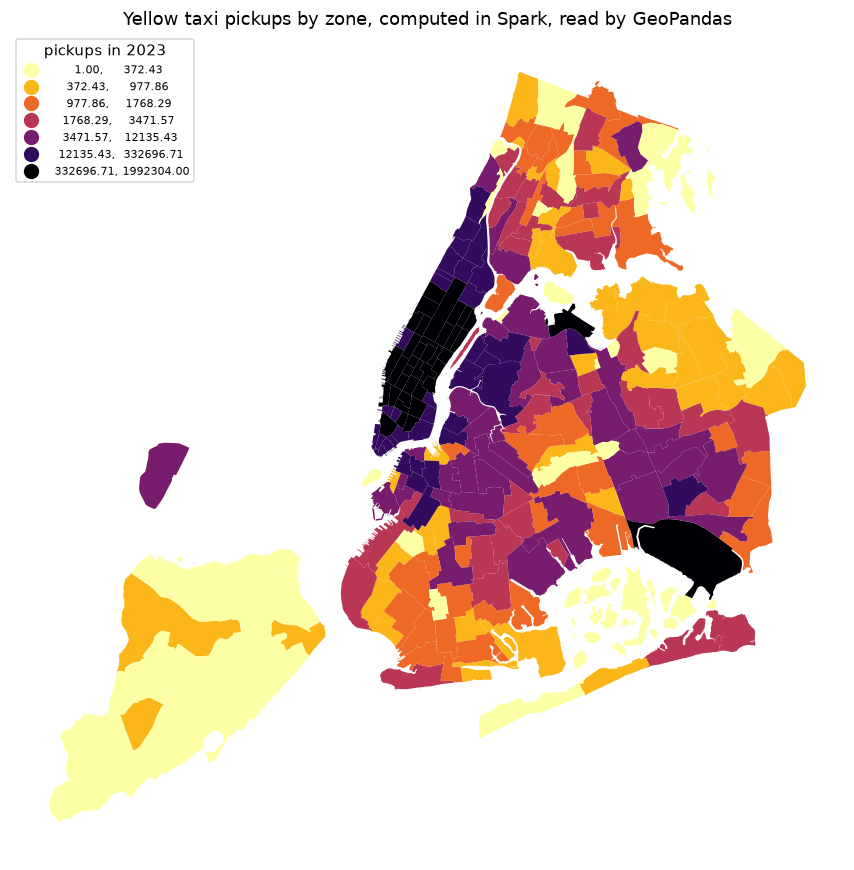

In [9]:
out_sdf = spark.sql("""
    SELECT z.LocationID, z.zone, z.borough, t.n AS pickups, z.geometry
    FROM (SELECT PULocationID, COUNT(*) AS n FROM trips GROUP BY PULocationID) t
    JOIN zones z ON z.LocationID = t.PULocationID
""")  # pickups with geometry
out_sdf.write.mode("overwrite").format("geoparquet").save(str(SP / "pickups_by_zone"))  # written by Spark, one file per partition
back = gpd.read_parquet(SP / "pickups_by_zone").set_crs(zones.crs, allow_override=True)  # read by GeoPandas
print(len(back), "zones read back;", len(list((SP / "pickups_by_zone").glob("*.parquet"))), "Parquet files")  # check
ax = back.plot("pickups", cmap="inferno_r", scheme="quantiles", k=7, legend=True, figsize=(8, 8),  # map
               legend_kwds={"fontsize": 7, "loc": "upper left", "title": "pickups in 2023"})  # legend
ax.set_title("Yellow taxi pickups by zone, computed in Spark, read by GeoPandas"); ax.set_axis_off(); plt.tight_layout(); plt.show()  # draw

In [10]:
pdist.sedona.stop()  # stop Spark
shutil.rmtree(SP)  # remove the scratch files

## Summary and exercises

- Spark runs lazy, optimized plans over partitions with executors; Sedona adds geometry types,
  `ST_` functions, spatial partitioning and spatial joins.
- `pdist.sedona.spark` starts a session with the matching Sedona JARs; `to_spark` and
  `to_geopandas` move data across the Python and JVM boundary.
- The county join gave identical pairs with GeoPandas, Dask and Sedona. With GeoPandas input on
  one machine, Dask was fastest, because Sedona paid to move the geometries into the JVM; with
  both inputs read by Spark, the join and aggregation ran inside Spark and only 105 rows came back,
  in about the same time.
- Spatial SQL combined `ST_Area`, `ST_DWithin`, `ST_Distance` and `ST_Contains` with ordinary
  aggregation of 38 million trips, and Spark wrote GeoParquet that GeoPandas read directly.

**Exercises**

1. Repeat the Spark-only join with `spark.sql.shuffle.partitions` set to 8 and to 200. How does the
   time change?
2. Use `ST_Buffer` to find the taxi zones within 1 mile of Central Park and count their pickups.
3. Join the buildings with themselves in Sedona (`ST_DWithin` with 20 m) to count each building's
   close neighbours; why would this be hard with the Dask engine?
4. Read the GeoParquet written by Spark with DuckDB's spatial extension and repeat one query.